# Srm-Open 教学示例：从指标到药型再到性能

本 notebook 演示正向设计的完整链路，并逐项打印所用模型与假设。
运行前请确保已安装本包（`pip install -e .`）或在仓库根目录运行。

> 所有数值来自内置占位数据库，仅用于教学。
> 说明：正向合成药柱与逆向优化均需迭代燃面计算，notebook 整体运行约 4-6 分钟。


In [1]:
from srm_open.api import design_forward, list_templates, list_propellants

print('templates :', list_templates())
print('propellants:', list_propellants())

templates : {'tube_simple': 'Simple central-bore tube (internal burning)', 'tube_both_ends': 'Uninhibited tube (inner + outer burning)', 'star_6_point': '6-point star (progressive-regressive)', 'star_8_point_filleted': '8-point filleted star', 'wagon_wheel_6': '6-spoke wagon wheel', 'slotted_6': '6-slot (internal-external)', 'finocyl_6': '6-fin finocyl', 'multi_perf_7': '7-perforation (classic multi-perf)', 'spherical_cavity': 'Spherical cavity (end burning)', 'conical_cavity': 'Conical cavity', 'end_burner': 'Solid cylinder (end burning)', 'two_segment_booster': 'Two-segment booster (tube + star)'}
propellants: {'ap_htpb_80': 'AP/HTPB 80/20 (generic)', 'ap_htpb_75_al': 'AP/Al/HTPB 75/15/10 (generic)', 'double_base_ng': 'Double-base (nitroglycerine) generic', 'ap_htpb_gibbs': 'AP/HTPB 80/20 (Gibbs-computed)'}


## 1. 输入初始总体指标

给定推力、工作时间、压强上限、外径与长径比。软件将自动完成：
指标校验 → 推进剂/喷管选择 → 药型选型 → 参数合成 → 燃面/内弹道/性能。

In [2]:
req = {
    'thrust': 8000.0,            # N
    'burn_time': 4.0,            # s
    'max_chamber_pressure': 9e6, # Pa
    'outer_diameter': 0.16,      # m
    'length_ratio': 5.0,
    'thrust_profile': 'neutral', # neutral | progressive | regressive
}
r = design_forward(req, 'ap_htpb_80')
print('synthesised family :', r.grain.segments[0].family.value)
print('grain parameters   :', r.grain.segments[0].params)
print('throat diameter    :', r.nozzle.throat_diameter)
print('peak pressure [MPa]:', r.ballistics.peak_pressure / 1e6)

synthesised family : star
grain parameters   : {'inner_diameter': 0.057999206650457394, 'point_diameter': 0.07328649792989292, 'point_half_angle': 44.39838032741939, 'n_points': 5.0}
throat diameter    : 0.037705292353955276
peak pressure [MPa]: 8.088871910175051


## 2. 性能与校核

`r.verification.checks` 给出每个校核项的通过与否与残差。

In [3]:
p = r.performance
print(f'avg thrust   : {p.average_thrust:.1f} N')
print(f'burn time    : {p.burn_time:.4f} s')
print(f'total impulse: {p.total_impulse:.1f} N.s')
print(f'Isp          : {p.specific_impulse:.1f} s')
print(f'prop mass    : {p.propellant_mass:.3f} kg')
for c in r.verification.checks:
    print(f"  {c['name']:<32} {'PASS' if c['passed'] else 'FAIL'}  {c.get('note','')}")

avg thrust   : 8008.2 N
burn time    : 4.0013 s
total impulse: 32043.0 N.s
Isp          : 208.1 s
prop mass    : 15.704 kg
  requirement_consistency          PASS  
  mass_flow_balance                PASS  mdot_gen vs mdot_out at equilibrium
  average_thrust_vs_requirement    PASS  dev=0.001
  total_impulse_vs_requirement     PASS  dev=0.0013
  burn_time_vs_requirement         PASS  dev=0.0003
  peak_pressure_below_limit        PASS  
  geometry_positive_dimensions     PASS  
  positive_web_thickness           PASS  
  grain_synthesis_mass             PASS  target 17.082 kg


## 3. 曲线：压强、推力、燃面

观察星形药柱的燃面先升后降，对应推力的渐进-退减形状。

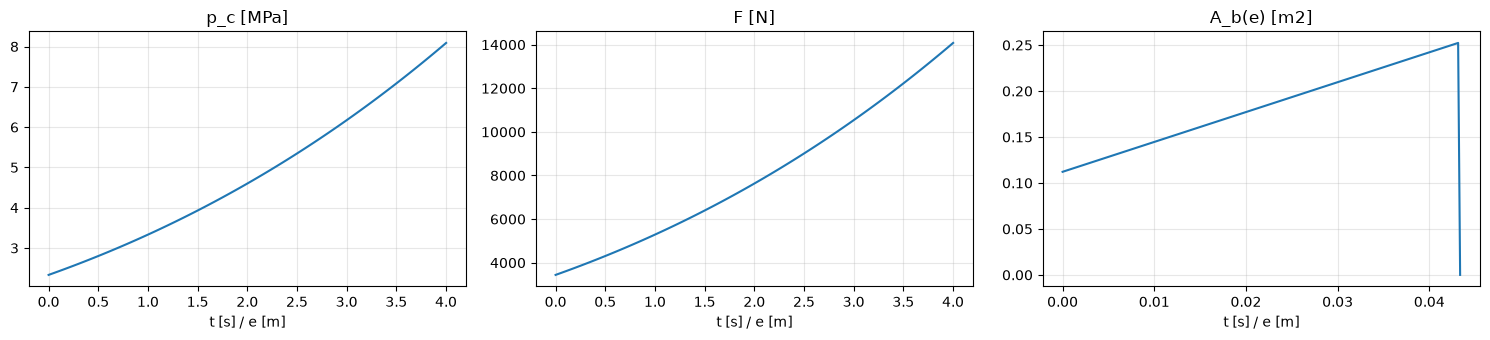

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(r.ballistics.time, [x/1e6 for x in r.ballistics.chamber_pressure]); ax[0].set_title('p_c [MPa]')
ax[1].plot(r.performance.time, r.performance.thrust); ax[1].set_title('F [N]')
ax[2].plot(r.burnback.burn_distance, r.burnback.burn_area); ax[2].set_title('A_b(e) [m2]')
for a in ax: a.set_xlabel('t [s] / e [m]'); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. 敏感性：改变压强上限

把 `max_chamber_pressure` 从 6 MPa 扫到 11 MPa，观察喉径、比冲与质量变化。

In [5]:
for pmax in [7e6, 11e6]:
    rr = design_forward({**req, 'max_chamber_pressure': pmax}, 'ap_htpb_80')
    print(f"p_max={pmax/1e6:4.0f} MPa -> d_t={rr.nozzle.throat_diameter*1e3:6.2f} mm "
          f"peak={rr.ballistics.peak_pressure/1e6:5.2f} MPa "
          f"Isp={rr.performance.specific_impulse:6.1f} s m_p={rr.performance.propellant_mass:5.2f} kg")

p_max=   7 MPa -> d_t= 41.69 mm peak= 6.29 MPa Isp= 215.1 s m_p=15.19 kg


p_max=  11 MPa -> d_t= 33.99 mm peak= 9.89 MPa Isp= 229.5 s m_p=14.22 kg


## 5. 逆向设计

给定目标推力/工作时间，反推星形药柱参数。

In [6]:
from srm_open.config import get_config
from srm_open.models.requirements import RequirementSet
from srm_open.models.grain import GrainFamily
from srm_open.inverse import default_design_space, inverse_design
from srm_open.api.facade import get_propellant

# Coarsen the numerics so the optimiser loop finishes in a couple of minutes.
cfg = get_config(); cfg.set('burnback.n_steps', 60); cfg.set('ballistics.time_steps', 120)

req2 = RequirementSet(name='inv', thrust=6000.0, burn_time=4.0,
                      max_chamber_pressure=9e6, outer_diameter=0.16)
space = default_design_space(GrainFamily.STAR, 0.16, (0.2, 0.8))
ri = inverse_design(req2, get_propellant('ap_htpb_80'), space, max_iter=6)
print('recovered params:', ri.grain.segments[0].params)
print('thrust:', ri.performance.average_thrust, 'burn time:', ri.performance.burn_time)


recovered params: {'inner_diameter': 0.017710027101940418, 'point_diameter': 0.06732743569735061, 'point_half_angle': 33.836592913902464, 'n_points': 10.0}
thrust: 6000.007413181134 burn time: 4.0000013898050915
